In [10]:
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

In [18]:
# Model colors - consistent across all plots
MODEL_COLORS = {
    'dino': '#0A5EB0',        # Blue
    'clip_image': '#DC143C',   # Crimson
    'clip_text': '#FF8C00',    # Dark Orange
    'deepseek': '#2E8B57',     # Sea Green
    'igpt': '#399918'          # Green (for future)
}

# Model display names
MODEL_NAMES = {
    'dino': 'DinoV2',
    'clip_image': 'CLIP-Image',
    'clip_text': 'CLIP-Text',
    'deepseek': 'DeepSeek-V3',
    'igpt': 'ImageGPT'
}

In [11]:
data_path = "../data/dino_igpt" if Path.is_dir("../data/dino_igpt") else "data/dino_igpt"

In [12]:
dino_igpt = np.load(Path(data_path, "dino_igpt_52.npy"))

In [13]:
igpt_dino = np.load(Path(data_path, "igpt_dino_52.npy"))

In [15]:
plt.plot()

(24, 500)

In [17]:
# Calculate statistics
forward_mean = np.mean(igpt_dino, axis=1)
forward_std = np.std(igpt_dino, axis=1)
backward_mean = np.mean(dino_igpt, axis=1)
backward_std = np.std(dino_igpt, axis=1)

In [20]:
n_layers = forward_mean.shape[0]
print(f"Layers: {n_layers}")
x = np.linspace(0., 1., n_layers)

Layers: 24


In [22]:
# Get colors
color_a = MODEL_COLORS.get("igpt", '#808080')
color_b = MODEL_COLORS.get("dino", '#808080')

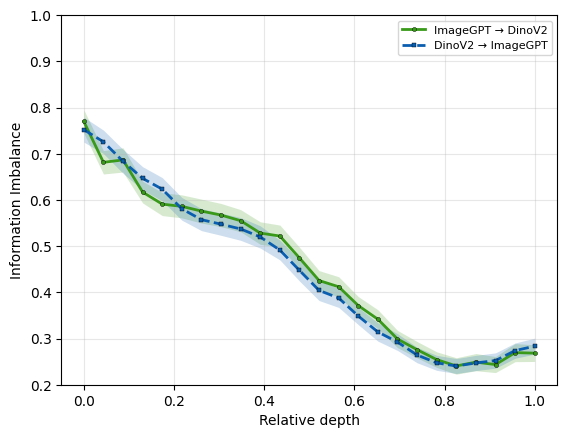

In [31]:
# Plot forward direction (A → B)
fig, ax = plt.subplots()
label_forward = f"{MODEL_NAMES["igpt"]} → {MODEL_NAMES["dino"]}"
ax.plot(x, forward_mean, '-', color=color_a, 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x, forward_mean - forward_std, forward_mean + forward_std, alpha=0.2, linewidth=0, color=color_a)
    
# Plot backward direction (B → A)
label_backward = f"{MODEL_NAMES["dino"]} → {MODEL_NAMES["igpt"]}"
ax.plot(x, backward_mean, '--', color=color_b, label=label_backward, linewidth=2, marker='s', markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x, backward_mean - backward_std, backward_mean + backward_std, alpha=0.2, linewidth=0, color=color_b)

# Customize subplot
title = f"{MODEL_NAMES["igpt"]} → {MODEL_NAMES["dino"]}"
layer = n_layers
tokens = 50
## ax.set_title(f"{title}\n(Layer {layer}, {tokens} tokens)", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=10)
ax.set_ylabel("Information Imbalance", fontsize=10)
ax.set_ylim(0.2, 1.0)
ax.legend(fontsize=8, loc='best')
ax.grid(True, alpha=0.3)